# Inspecting prepared, pre-matched data

Notebook purpose:
- Inspect the added variables
- Inspect identification characteristics before matching

#### 1. Set-up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import scipy
from datetime import datetime

Load paths and data

In [25]:
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig

from ipcei_spillovers.plotting import (
    COLORS,
    style_ax
)

In [28]:
# ============================================================
# Load data
# ============================================================

firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_corrected_extended_jan26.csv", low_memory=False
)
partnership_master_ipcei = load_df(
    "interim", "combined", "partnership_master_ipcei_jan26.csv", low_memory=False
)

print(f"firm_master_ipcei: {firm_master_ipcei.shape}")
print(f"partnership_master_ipcei: {partnership_master_ipcei.shape}")

firm_master_ipcei: (239782, 128)
partnership_master_ipcei: (3943633, 74)


#### 2. Adapted firm characteristics

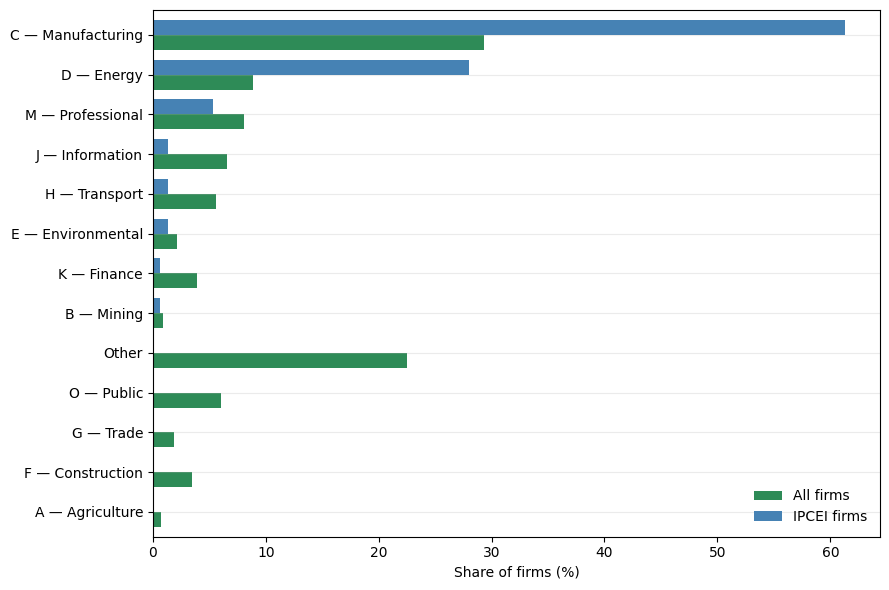

In [29]:
# ============================================================
# Sector composition — NACE proxy, IPCEI firms only
# ============================================================

fm = firm_master_ipcei.copy()

fm["treated_flag"] = np.where(
    fm["treated_any"] == 1,
    "IPCEI firms",
    "All firms"
)

# Compute shares safely
counts = pd.crosstab(
    fm["nace1_proxy"],
    fm["treated_flag"],
    normalize="columns"
) * 100

plot_df = counts.sort_values("IPCEI firms")

# Plot
fig, ax = plt.subplots(figsize=(9,6))

plot_df.plot(
    kind="barh",
    ax=ax,
    color=[COLORS["two"][1], COLORS["two"][0]],
    width=0.75
)

ax.set_xlabel("Share of firms (%)")
ax.set_ylabel("")

style_ax(ax)
ax.legend(frameon=False)

plt.tight_layout()

save_fig(fig, "descriptives_prematch", "firms_all_naceproxy_barchart")

plt.show()


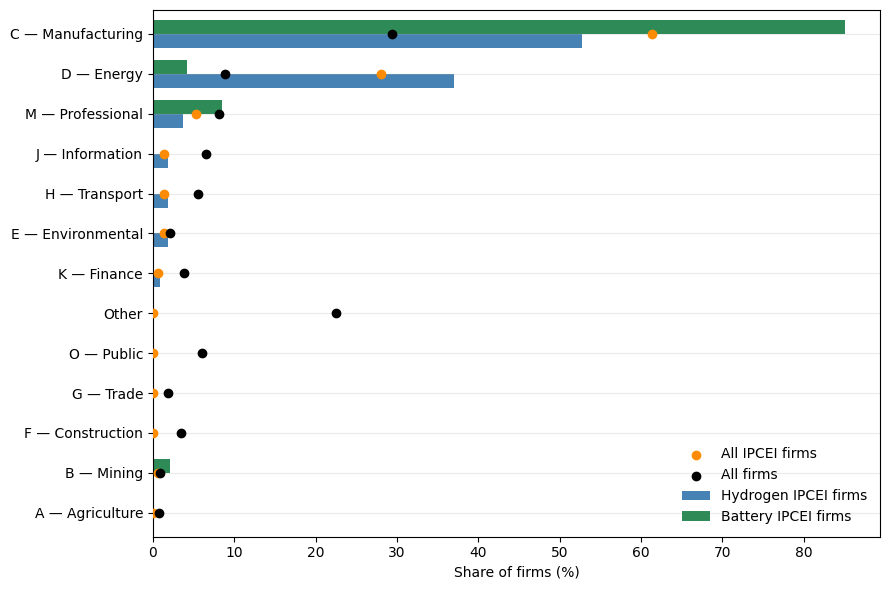

In [30]:
# ============================================================
# Sector composition — NACE-1 proxy, all firms
# ============================================================

fm = firm_master_ipcei.copy()

# IPCEI type flags
types_lc = fm["ipcei_types"].astype("string").str.lower()
fm["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
fm["is_battery"]  = types_lc.str.contains("battery",  na=False)

treated = fm.loc[fm["treated_any"].fillna(0).astype(int) == 1]

# Compute shares per group
def nace_share(df):
    return df["nace1_proxy"].value_counts(normalize=True).mul(100)

share_h2   = nace_share(treated.loc[treated["is_hydrogen"]])
share_batt = nace_share(treated.loc[treated["is_battery"]])
share_ipcei = nace_share(treated)
share_all   = nace_share(fm)

# Align on common index, sort by Hydrogen share
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":            share_all,
}).fillna(0)

plot_df = plot_df.sort_values("Hydrogen IPCEI firms")

# Plot
fig, ax = plt.subplots(figsize=(9, 6))

# Bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

# Dot: All IPCEI firms
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],
    zorder=3,
    label="All IPCEI firms"
)

# Dot: All firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms"
)

ax.set_xlabel("Share of firms (%)")
ax.set_ylabel("")

style_ax(ax)
ax.legend(frameon=False)

plt.tight_layout()

save_fig(fig, "descriptives_prematch", "firms_all_naceproxy_barchart")
plt.show()

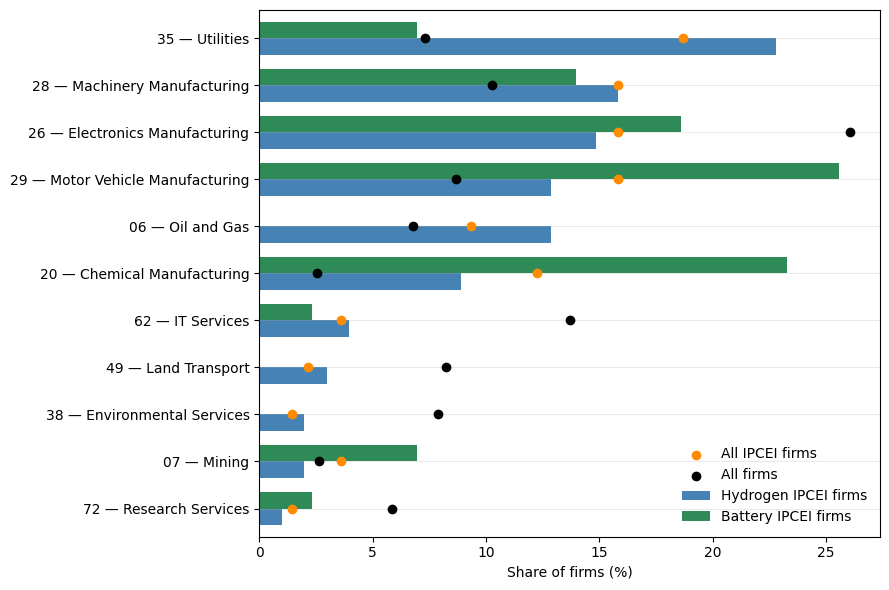

In [32]:
# ============================================================
# Sector composition — NACE-2 proxy, all firms
# ============================================================

fm = firm_master_ipcei.copy()

# IPCEI type flags
types_lc = fm["ipcei_types"].astype("string").str.lower()
fm["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
fm["is_battery"]  = types_lc.str.contains("battery",  na=False)

treated = fm.loc[fm["treated_any"].fillna(0).astype(int) == 1]

# Compute shares per group
def nace_share(df):
    return df["nace2_industry"].value_counts(normalize=True).mul(100)

share_h2   = nace_share(treated.loc[treated["is_hydrogen"]])
share_batt = nace_share(treated.loc[treated["is_battery"]])
share_ipcei = nace_share(treated)
share_all   = nace_share(fm)

# Align on common index, sort by Hydrogen share
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":            share_all,
}).fillna(0)

plot_df = plot_df.sort_values("Hydrogen IPCEI firms")

# Plot
fig, ax = plt.subplots(figsize=(9, 6))

# Bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

# Dot: All IPCEI firms
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],
    zorder=3,
    label="All IPCEI firms"
)

# Dot: All firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms"
)

ax.set_xlabel("Share of firms (%)")
ax.set_ylabel("")

style_ax(ax)
ax.legend(frameon=False)

plt.tight_layout()

save_fig(fig, "descriptives_prematch", "firms_all_nace2proxy_barchart")
plt.show()

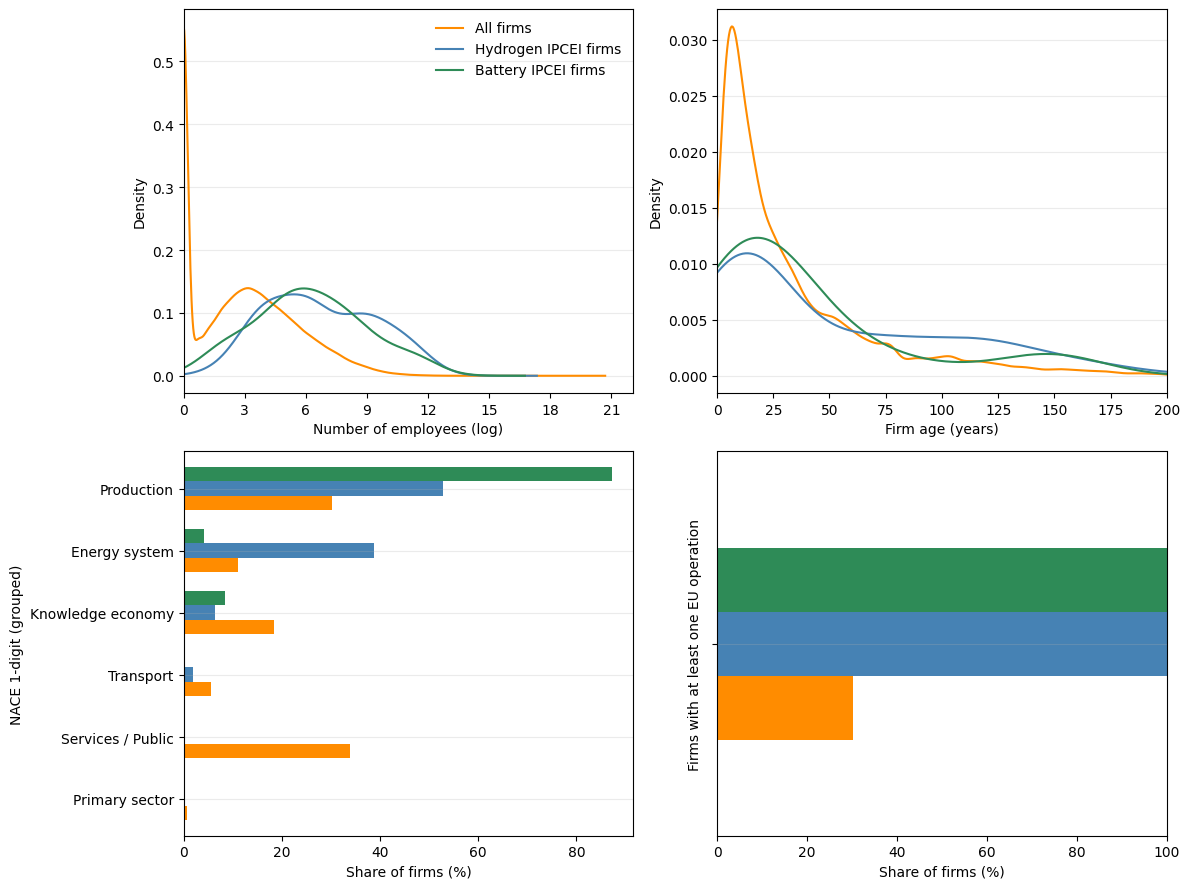

In [31]:
# ============================================================
# Firm characteristics - 4 panels
# ============================================================

firm_master_ipcei.loc[firm_master_ipcei["foundingYear"] < 400, "age"] = np.nan
fm = firm_master_ipcei.copy()

treated = fm["treated_any"] == 1

# IPCEI type flags
types_lc = fm["ipcei_types"].astype("string").str.lower()
fm["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
fm["is_battery"]  = types_lc.str.contains("battery",  na=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# ------------------------------------------------------------
# A — Log staff count
# ------------------------------------------------------------
ax = axes[0,0]

np.log1p(fm.loc[~treated, "staffCount"]).plot(
    kind="density", ax=ax, color=COLORS["three"][2], label="All firms"
)
np.log1p(fm.loc[treated & fm["is_hydrogen"], "staffCount"]).plot(
    kind="density", ax=ax, color=COLORS["three"][0], label="Hydrogen IPCEI firms"
)
np.log1p(fm.loc[treated & fm["is_battery"], "staffCount"]).plot(
    kind="density", ax=ax, color=COLORS["three"][1], label="Battery IPCEI firms"
)

ax.set_xlabel("Number of employees (log)")
ax.set_xlim(0, None)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
style_ax(ax)
ax.legend(frameon=False, fontsize=10)

# ------------------------------------------------------------
# B — Age
# ------------------------------------------------------------
ax = axes[0,1]

for mask, color in [
    (~treated,                    COLORS["three"][2]),
    (treated & fm["is_hydrogen"], COLORS["three"][0]),
    (treated & fm["is_battery"],  COLORS["three"][1]),
]:
    data = fm.loc[mask, "age"].dropna()
    data = data[(data >= 0) & (data <= 200)]
    data.plot(kind="density", ax=ax, color=color)

ax.set_xlabel("Firm age (years)")
ax.set_xlim(0, 200)
style_ax(ax)

# ------------------------------------------------------------
# C — NACE proxy composition
# ------------------------------------------------------------
ax = axes[1,0]

shares = pd.DataFrame({
    "All firms":            fm["nace1_psm"].value_counts(normalize=True).mul(100),
    "Hydrogen IPCEI firms": fm.loc[treated & fm["is_hydrogen"], "nace1_psm"].value_counts(normalize=True).mul(100),
    "Battery IPCEI firms":  fm.loc[treated & fm["is_battery"],  "nace1_psm"].value_counts(normalize=True).mul(100),
}).fillna(0)

shares.sort_values("Hydrogen IPCEI firms").plot(
    kind="barh",
    ax=ax,
    color=[COLORS["three"][2], COLORS["three"][0], COLORS["three"][1]],
    width=0.7
)

ax.set_xlabel("Share of firms (%)")
ax.set_ylabel("NACE 1-digit (grouped)")
style_ax(ax)
ax.get_legend().remove()

# ------------------------------------------------------------
# D — EU operations (dummy)
# ------------------------------------------------------------
ax = axes[1,1]

eu_shares = pd.DataFrame({
    "All firms":            [fm.loc[~treated,                    "has_eu_operation"].mean() * 100],
    "Hydrogen IPCEI firms": [fm.loc[treated & fm["is_hydrogen"], "has_eu_operation"].mean() * 100],
    "Battery IPCEI firms":  [fm.loc[treated & fm["is_battery"],  "has_eu_operation"].mean() * 100],
}, index=[""])

eu_shares.plot(
    kind="barh",
    ax=ax,
    color=[COLORS["three"][2], COLORS["three"][0], COLORS["three"][1]],
    width=0.5
)

ax.set_xlabel("Share of firms (%)")
ax.set_ylabel("Firms with at least one EU operation")
ax.set_xlim(0, 100)
style_ax(ax)
ax.get_legend().remove()

plt.tight_layout()

save_fig(fig, "descriptives_prematch", "firms_all_characteristics_4panels")
plt.show()

#### 3. Collaboration and centralities

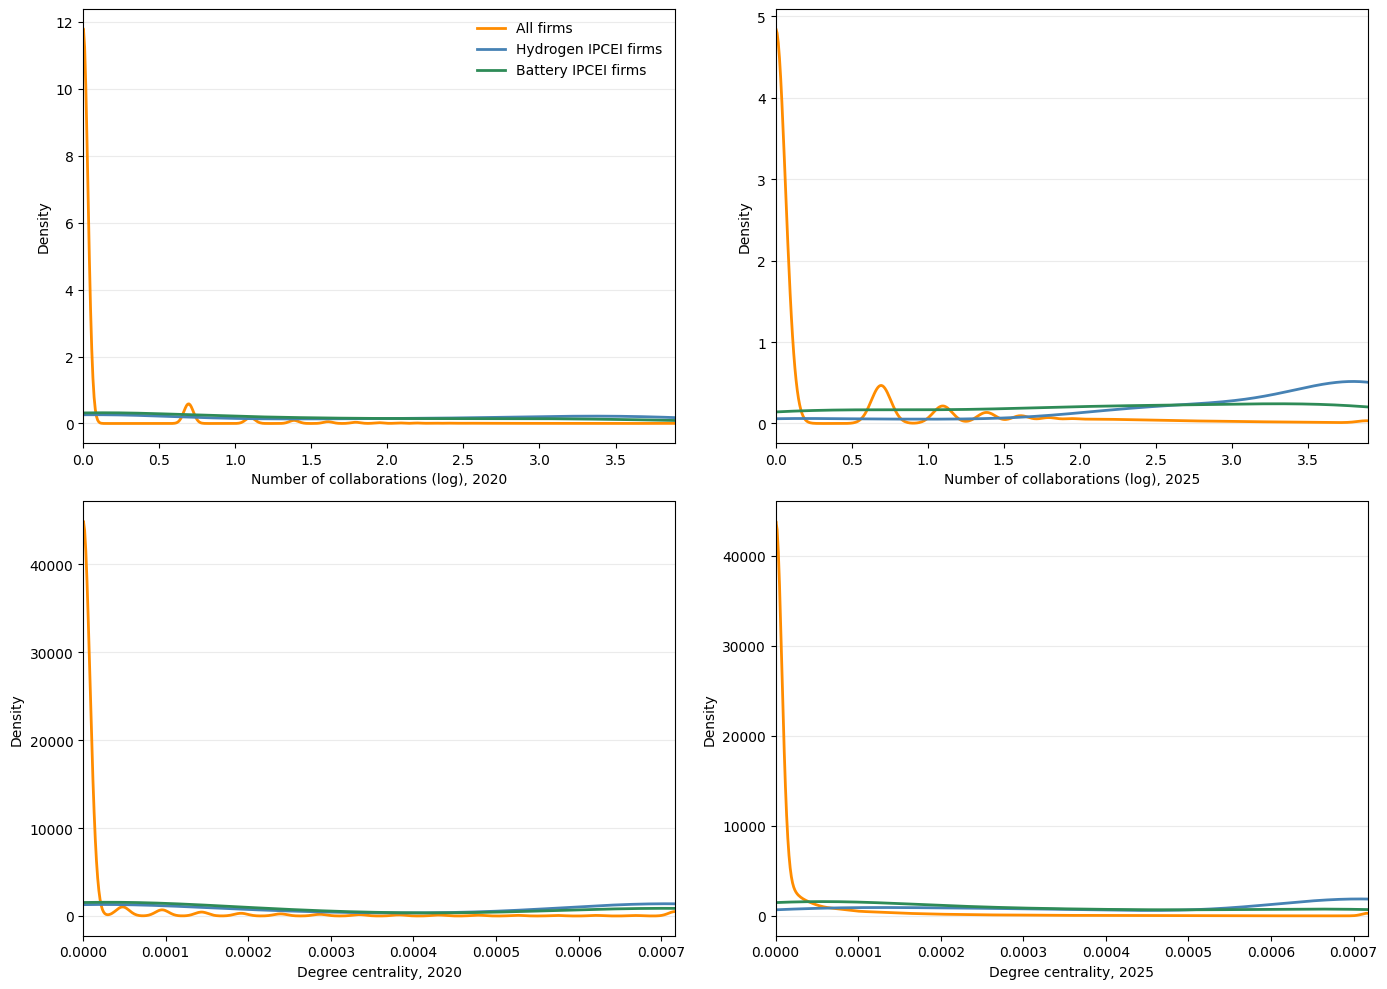

In [23]:
# ============================================================
# Baseline collaboration & network position — 4 panels
# ============================================================

fm = firm_master_ipcei.copy()
treated = fm["treated_any"] == 1

# IPCEI type flags
types_lc = fm["ipcei_types"].astype("string").str.lower()
fm["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
fm["is_battery"]  = types_lc.str.contains("battery",  na=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

upper_collab_2020 = fm["log_collab_count_2020"].quantile(0.995)
upper_collab_2025 = fm["log_collab_count_2025"].quantile(0.995) if "log_collab_count_2025" in fm.columns else upper_collab_2020
upper_collab = max(upper_collab_2020, upper_collab_2025)

upper_degree_2020 = fm["degree_centrality_2020"].quantile(0.99)
upper_degree_2025 = fm["degree_centrality_2025"].quantile(0.99) if "degree_centrality_2025" in fm.columns else upper_degree_2020
upper_degree = max(upper_degree_2020, upper_degree_2025)

# Helper to plot three lines consistently
def plot_three(ax, col, upper, xlabel, show_legend=False):
    groups = [
        (~treated,                    COLORS["three"][2], "All firms"),
        (treated & fm["is_hydrogen"], COLORS["three"][0], "Hydrogen IPCEI firms"),
        (treated & fm["is_battery"],  COLORS["three"][1], "Battery IPCEI firms"),
    ]
    for mask, color, label in groups:
        data = fm.loc[mask, col].dropna().clip(upper=upper)
        data.plot(kind="density", ax=ax, color=color, label=label, linewidth=2)

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.set_xlim(0, upper)
    style_ax(ax)
    if show_legend:
        ax.legend(frameon=False, loc="upper right")
    else:
        ax.get_legend().remove() if ax.get_legend() else None

# --------------------------------------------------
# Panel A: Collaboration count 2020
# --------------------------------------------------
plot_three(axes[0,0], "log_collab_count_2020", upper_collab,
           "Number of collaborations (log), 2020", show_legend=True)

# --------------------------------------------------
# Panel B: Collaboration count 2025
# --------------------------------------------------
plot_three(axes[0,1], "log_collab_count_2025", upper_collab,
           "Number of collaborations (log), 2025")

# --------------------------------------------------
# Panel C: Degree centrality 2020
# --------------------------------------------------
plot_three(axes[1,0], "degree_centrality_2020", upper_degree,
           "Degree centrality, 2020")

# --------------------------------------------------
# Panel D: Degree centrality 2025
# --------------------------------------------------
plot_three(axes[1,1], "degree_centrality_2025", upper_degree,
           "Degree centrality, 2025")

plt.tight_layout()
save_fig(fig, "descriptives_prematch", "collaborations_centrality-counts_2020-2025_4panels")
plt.show()

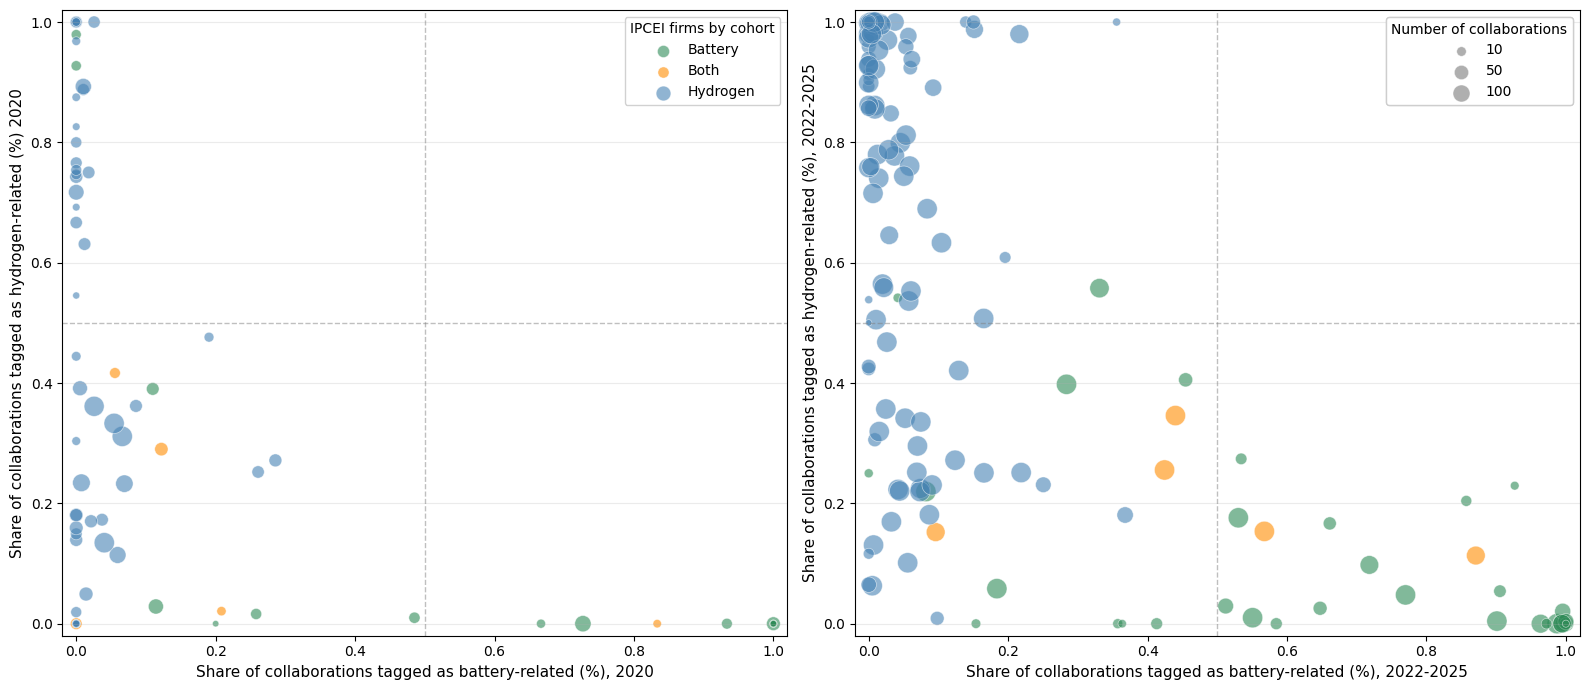


Firms with 2020 data: 90
Firms with post-2022 data: 144


In [9]:
# ============================================================
# Tech portfolio bubble chart: Baseline (2020) vs Post-treatment (2022+)
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# IPCEI firms
ipcei_firms = fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
                     ["Linkedin_name", "ipcei_types"]].copy()
ipcei_firms = ipcei_firms.dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

# Prepare partnership data
cols = ["source", "target", "Hydrogen", "Battery", "collaboration_id", "post_date"]
tmp = p[cols].copy()

tmp["Hydrogen"] = pd.to_numeric(tmp["Hydrogen"], errors="coerce").fillna(0).astype(int)
tmp["Battery"] = pd.to_numeric(tmp["Battery"], errors="coerce").fillna(0).astype(int)

# Extract year from post_date
tmp["year"] = pd.to_datetime(tmp["post_date"], errors="coerce").dt.year

# Endpoint table
src = tmp.rename(columns={"source": "Linkedin_name"})[["Linkedin_name", "collaboration_id", "Hydrogen", "Battery", "year"]]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[["Linkedin_name", "collaboration_id", "Hydrogen", "Battery", "year"]]
endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name", "collaboration_id"])

# ========== INSERT THE FILTERING HERE ==========

# --- BASELINE 2020 ---
endp_2020 = endp[endp["year"] == 2020].copy()
firm_tech_2020 = (
    endp_2020.groupby("Linkedin_name", as_index=False)
        .agg(
            n_collabs=("collaboration_id", "nunique"),
            share_hydrogen=("Hydrogen", "mean"),
            share_battery=("Battery", "mean"),
        )
)

# --- POST-TREATMENT 2022-2024 (exclude baseline years 2020-2021) ---
endp_post = endp[endp["year"] >= 2022].copy()
firm_tech_post = (
    endp_post.groupby("Linkedin_name", as_index=False)
        .agg(
            n_collabs=("collaboration_id", "nunique"),
            share_hydrogen=("Hydrogen", "mean"),
            share_battery=("Battery", "mean"),
        )
)

# ========== CONTINUE WITH MERGING ==========

# Merge onto IPCEI firms
ip_2020 = ipcei_firms.merge(firm_tech_2020, on="Linkedin_name", how="left")
ip_post = ipcei_firms.merge(firm_tech_post, on="Linkedin_name", how="left")  # Changed from ip_total

for ip in [ip_2020, ip_post]:  # Changed from ip_total
    ip[["n_collabs", "share_hydrogen", "share_battery"]] = \
        ip[["n_collabs", "share_hydrogen", "share_battery"]].fillna(0)

    ip["ipcei_type_group"] = (
        ip["ipcei_types"].astype("string").str.lower().fillna("")
          .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
                          else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                                else ("Both" if ("battery" in s and "hydrogen" in s)
                                      else "Unknown")))
    )

# Color map
color_map = {
    "Hydrogen": COLORS["three"][0],
    "Battery": COLORS["three"][1],
    "Both": COLORS["three"][2],
}

# --- Create 2-panel figure ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --------------------------------------------------
# Panel A: Baseline 2020
# --------------------------------------------------
ax = axes[0]

plot_df_2020 = ip_2020.loc[ip_2020["n_collabs"] > 0].copy()
sizes_2020 = np.sqrt(plot_df_2020["n_collabs"].clip(upper=200)) * 15

for grp, sub in plot_df_2020.groupby("ipcei_type_group"):
    if grp not in ["Hydrogen", "Battery", "Both"]:
        continue

    ax.scatter(
        sub["share_battery"],
        sub["share_hydrogen"],
        s=sizes_2020.loc[sub.index],
        alpha=0.6,
        color=color_map.get(grp, "grey"),
        label=grp,
        edgecolors="white",
        linewidth=0.5,
    )

ax.axvline(0.5, linestyle="--", linewidth=1, color="grey", alpha=0.5)
ax.axhline(0.5, linestyle="--", linewidth=1, color="grey", alpha=0.5)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("Share of collaborations tagged as battery-related (%), 2020", fontsize=11)
ax.set_ylabel("Share of collaborations tagged as hydrogen-related (%) 2020", fontsize=11)
ax.set_title("Pre-treatment (2020)", fontsize=12, fontweight='bold')  # Updated title

style_ax(ax)
ax.legend(title="IPCEI firms by cohort", loc="upper right", framealpha=0.9)

# --------------------------------------------------
# Panel B: Post-treatment 2022+
# --------------------------------------------------
ax = axes[1]

plot_df_post = ip_post.loc[ip_post["n_collabs"] > 0].copy()  # Changed from plot_df_total
sizes_post = np.sqrt(plot_df_post["n_collabs"].clip(upper=200)) * 15  # Changed from sizes_total

for grp, sub in plot_df_post.groupby("ipcei_type_group"):
    if grp not in ["Hydrogen", "Battery", "Both"]:
        continue

    ax.scatter(
        sub["share_battery"],
        sub["share_hydrogen"],
        s=sizes_post.loc[sub.index],
        alpha=0.6,
        color=color_map.get(grp, "grey"),
        label=grp,
        edgecolors="white",
        linewidth=0.5,
    )

ax.axvline(0.5, linestyle="--", linewidth=1, color="grey", alpha=0.5)
ax.axhline(0.5, linestyle="--", linewidth=1, color="grey", alpha=0.5)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("Share of collaborations tagged as battery-related (%), 2022-2025", fontsize=11)
ax.set_ylabel("Share of collaborations tagged as hydrogen-related (%), 2022-2025", fontsize=11)
ax.set_title("Post-treatment (2022-2024)", fontsize=12, fontweight='bold')  # Updated title

style_ax(ax)
ax.legend(title="IPCEI firms by cohort", loc="upper right", framealpha=0.9)

# Add size legend to second panel
size_values = [10, 50, 100]
size_legend_handles = [
    plt.scatter([], [], s=np.sqrt(v) * 15, c='grey', alpha=0.6, edgecolors="white", linewidth=0.5)
    for v in size_values
]
size_legend = ax.legend(
    size_legend_handles,
    [f"{v}" for v in size_values],
    title="Number of collaborations",
    loc="upper right",
    framealpha=0.9,
    scatterpoints=1,
)
ax.add_artist(size_legend)

# Re-add main legend
#main_legend = ax.legend(
#    *[ax.get_legend_handles_labels()[i] for i in [0, 1]],
#    title="IPCEI type",
#    loc="upper right",
#    framealpha=0.9,
#)

plt.tight_layout()
save_fig(fig, "descriptives_prematch", "collaborations_tech-specialization_bubblechart")  # Updated filename
plt.show()

print(f"\nFirms with 2020 data: {len(plot_df_2020)}")
print(f"Firms with post-2022 data: {len(plot_df_post)}")  # Updated print

#### 4. Treatment timing

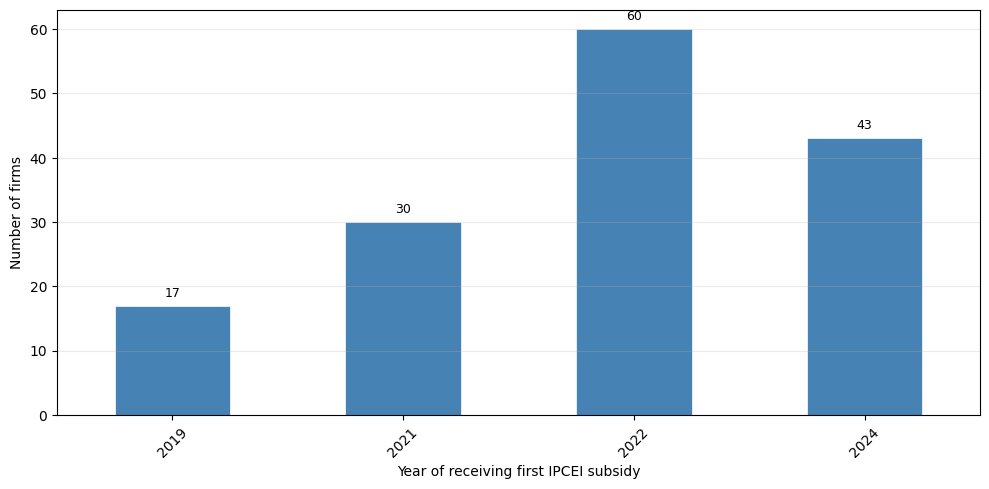


Total treated firms: 150
Treatment year range: 2019-2024


In [10]:
# ============================================================
# IPCEI treatment timing
# ============================================================

fm = firm_master_ipcei.copy()
treated_firms = fm[fm["treated_any"] == 1].copy()

# Extract first treatment year
treated_firms["first_ipcei_year"] = pd.to_datetime(
    treated_firms["first_ipcei_date"], errors="coerce"
).dt.year

fig, ax = plt.subplots(figsize=(10, 5))

# Bar chart of treatment years
year_counts = treated_firms["first_ipcei_year"].value_counts().sort_index()

year_counts.plot(
    kind="bar",
    ax=ax,
    color=COLORS["one"],
    edgecolor="white",
    linewidth=0.5
)

ax.set_xlabel("Year of receiving first IPCEI subsidy")
ax.set_ylabel("Number of firms")
ax.set_title("IPCEI treatment timing")
ax.tick_params(axis="x", rotation=45)

# Add value labels on bars
for i, v in enumerate(year_counts):
    ax.text(i, v + 1, str(v), ha='center', va='bottom', fontsize=9)

style_ax(ax)
plt.tight_layout()
save_fig(fig, "descriptives_prematch", "firms_ipcei_treatment_barchart")
plt.show()

print(f"\nTotal treated firms: {len(treated_firms)}")
print(f"Treatment year range: {year_counts.index.min()}-{year_counts.index.max()}")